In [1]:
### Basic deep agent

import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENROUTER_API_KEY"]=os.getenv("OPENROUTER_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

### Context Engineering- Input context- System Prompt

In [2]:
from deepagents import create_deep_agent
from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model="nvidia/nemotron-3-ultra-550b-a55b:free",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1"
)




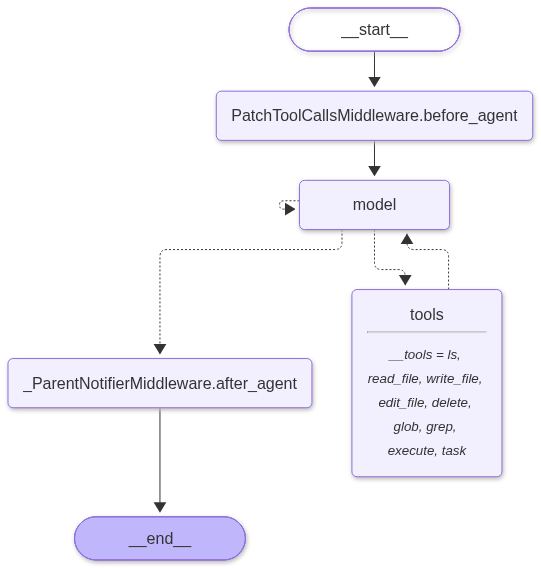

In [3]:
agent=create_deep_agent(
    model=model,
    system_prompt=(
        "You are a research assistant specializing in scientific literature. "
        "Always cite sources. Use subagents for parallel research on different topics."

    ),
)
agent

In [4]:
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='f79c9433-0570-47d9-bee4-fa799985e882'),
  AIMessage(content='I\'ll search for information about "deepagent" to provide you with an accurate answer.\n', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 77, 'prompt_tokens': 2925, 'total_tokens': 3002, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 32, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}}, 'model_provider': 'openai', 'model_name': 'nvidia/nemotron-3-ultra-550b-a55b:free', 'system_fingerprint':

## Context Engineering with AGENTS.md

In [5]:
from pathlib import Path
agents_md=Path("projects/AGENTS.md").read_text(encoding="utf-8")
agents_md

'# Agents.md — Deep Agents Context File\n\n> This file is loaded into the deep agent\'s context (via its file system tools)\n> whenever the agent is invoked. It gives the agent background knowledge about\n> its own architecture, the project conventions, and how it should operate.\n\n---\n\n## 1. What is a Deep Agent?\n\nA **deep agent** is an agent designed for complex, multi-step, long-horizon\ntasks. Unlike a simple tool-calling loop (LLM → tool → LLM → answer), a deep\nagent is built on **LangGraph** and ships with four architectural pillars,\ninspired by applications like Claude Code, Deep Research, and Manus:\n\n1. **Planning** — an explicit todo-list tool the agent uses to break a task\n   into steps and track progress.\n2. **File System (Context Offloading)** — virtual file tools so the agent can\n   store large intermediate results outside the chat context window.\n3. **Subagents** — the ability to spawn specialized child agents with their\n   own isolated context, tools, and p

In [6]:
from langgraph.checkpoint.memory import MemorySaver
checkpointer=MemorySaver()

### Memory

In [7]:
agent = create_deep_agent(
    model=model,
    checkpointer=MemorySaver(),
    # no backend, no memory=, no files=
)
result = agent.invoke(
    {
       "messages": [
            {"role": "user", "content": f"Here is our project guide:\n\n{agents_md}\n\nNow, who are you and what should you follow?"}
        ]
    },
    config={"configurable": {"thread_id": "default-demo-1"}},  # fresh thread => memory loads
)
print(result["messages"][-1].content)

Based on the **Agents.md** context file you've provided, I am a **Deep Agent** — an agent designed for complex, multi-step, long-horizon tasks built on **LangGraph** with four architectural pillars:

1. **Planning** — I maintain a structured todo list via `write_todos` to break tasks into steps and track progress
2. **File System** — I use `ls`, `read_file`, `write_file`, `edit_file` to offload large intermediate results out of the context window
3. **Subagents** — I can delegate self-contained work to isolated child agents via the `task` tool
4. **System Prompt** — I follow detailed instructions (including this file) for when/how to use the above

---

## What I Follow (Operating Guidelines from §4)

| Guideline | My Behavior |
|-----------|-------------|
| **Plan first** | For any task >~2 steps, I call `write_todos` before starting and keep statuses updated |
| **Offload aggressively** | Raw research, long drafts, bulky outputs → written to files; conversation stays lean |
| **Deleg

In [8]:
agent=create_deep_agent(
    model=model,
    memory=["/projects/AGENTS.md"],
    checkpointer=MemorySaver(),
)

In [9]:
from deepagents.backends.utils import create_file_data
create_file_data(agents_md)

{'content': '# Agents.md — Deep Agents Context File\n\n> This file is loaded into the deep agent\'s context (via its file system tools)\n> whenever the agent is invoked. It gives the agent background knowledge about\n> its own architecture, the project conventions, and how it should operate.\n\n---\n\n## 1. What is a Deep Agent?\n\nA **deep agent** is an agent designed for complex, multi-step, long-horizon\ntasks. Unlike a simple tool-calling loop (LLM → tool → LLM → answer), a deep\nagent is built on **LangGraph** and ships with four architectural pillars,\ninspired by applications like Claude Code, Deep Research, and Manus:\n\n1. **Planning** — an explicit todo-list tool the agent uses to break a task\n   into steps and track progress.\n2. **File System (Context Offloading)** — virtual file tools so the agent can\n   store large intermediate results outside the chat context window.\n3. **Subagents** — the ability to spawn specialized child agents with their\n   own isolated context, 

In [10]:
result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What's in your memory? Who are you?"}],
        "files": {"/projects/AGENTS.md": create_file_data(agents_md)},  # seed the in-state file
    },
    config={"configurable": {"thread_id": "default-demo-1"}},  # fresh thread => memory loads
)
print(result["messages"][-1].content)

Based on the `Agents.md` file loaded into my context, I'm a **deep agent** — a sophisticated AI agent built on LangGraph with four core capabilities:

## My Architecture
1. **Planning** – I maintain a structured todo list (`write_todos`) to break complex tasks into steps and track progress
2. **File System** – Virtual file tools (`ls`, `read_file`, `write_file`, `edit_file`) let me offload large context (research notes, drafts, search results) out of the conversation window
3. **Subagents** – I can spawn specialized child agents with isolated context for deep-dive research or independent subtasks
4. **System Prompt** – A detailed prompt teaches me when and how to use the above capabilities

## My Operating Guidelines
- **Plan first** for multi-step tasks
- **Offload aggressively** – write bulky outputs to files, keep chat lean
- **Delegate wisely** – use subagents for self-contained research
- Treat this `Agents.md` as my authoritative architecture reference

## What's In My Memory Rig

In [11]:
# --- StoreBackend: persistent, cross-thread memory ---
# WHY: files/memory live in a LangGraph BaseStore, NOT in one conversation's state.
# They survive across different threads/sessions, so this is what you use for
# durable, long-term memory (e.g. per-user preferences the agent should recall
# next week). Here InMemoryStore is used for the demo; swap in a persistent store
# (e.g. Postgres) for real persistence.
from deepagents import create_deep_agent
from deepagents.backends.store import StoreBackend
from langgraph.store.memory import InMemoryStore
from langgraph.checkpoint.memory import MemorySaver

store = InMemoryStore()
# Seed durable memory into the store once. Namespace + key identify the file.
store.put(("memories",), "AGENTS.md", create_file_data(agents_md))

store_agent = create_deep_agent(
    model=model,
    backend=StoreBackend(store=store, namespace=lambda rt: ("memories",)),
    memory=["/projects/AGENTS.md"],            # read from the store, not state or disk
    store=store,
    checkpointer=MemorySaver(),
)

# Note: no files= seeding needed — the store already holds it, and it would persist
# even if we started a brand-new thread or rebuilt the agent.
result = store_agent.invoke(
    {"messages": [{"role": "user", "content": "What's in your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "store-demo-1"}},
)
print(result["messages"][-1].content)

I don't have any memory loaded - my memory file doesn't exist yet. I'm an AI assistant ready to help you with various tasks like coding, research, analysis, and more. I can use tools to read/write files, search codebases, and run commands.

Is there something specific you'd like me to help you with? If you have preferences or context you'd like me to remember for future interactions, just let me know!


In [12]:
result

{'messages': [HumanMessage(content="What's in your memory? Who are you?", additional_kwargs={}, response_metadata={}, id='41b487fd-ca7e-4514-9be3-786dea7607e5'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 60, 'prompt_tokens': 4019, 'total_tokens': 4079, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 24, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}}, 'model_provider': 'openai', 'model_name': 'nvidia/nemotron-3-ultra-550b-a55b:free', 'system_fingerprint': None, 'id': 'gen-1794864983-e606nQ5S9wg6wtKPf79L', 'finish_reason': 't

In [13]:
# --- FilesystemBackend: read files/memory straight from DISK ---
# WHY: the agent's files and memory map to real files on disk under root_dir.
# Nothing to seed — if AGENTS.md exists on disk, memory just loads it. Best for
# project context (AGENTS.md, docs, code) that already lives in your repo.
from deepagents import create_deep_agent
from deepagents.backends.filesystem import FilesystemBackend
from langgraph.checkpoint.memory import MemorySaver

# root_dir = the projects/ folder, so paths are resolved relative to it.
# AGENTS.md sits directly inside projects/, so the memory path is just "AGENTS.md".
# virtual_mode=True confines the agent to root_dir (blocks '..' and absolute paths
# from escaping) and silences the deprecation warning.
fs_agent = create_deep_agent(
    model=model,
    backend=FilesystemBackend(root_dir="projects", virtual_mode=True),
    memory=["AGENTS.md"],                             # -> projects/AGENTS.md
    checkpointer=MemorySaver(),
)

# Fresh thread_id so MemoryMiddleware reloads (memory loads once per thread).
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What's in your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "fs-demo-2"}},
)
print(result["messages"][-1].content)

Based on the `Agents.md` file loaded into my context, I'm a **deep agent** built on LangGraph with four architectural pillars:

1. **Planning** – I use `write_todos` to break tasks into steps and track progress
2. **File System** – I have virtual file tools (`ls`, `read_file`, `write_file`, `edit_file`) to offload context from the conversation window
3. **Subagents** – I can spawn specialized child agents with isolated context via the `task` tool
4. **Detailed System Prompt** – I follow a long, carefully engineered prompt (supplemented by context files like `Agents.md`)

**My current memory contains:**
- The `Agents.md` file you see above, which describes my own architecture and operating guidelines
- General knowledge from my training as an LLM

**What I don't have** (unless you've told me in this conversation):
- Personal information about you
- Persistent memories from previous sessions
- API keys or credentials

I operate by planning first for multi-step tasks, offloading bulky dat

In [14]:
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What is LLM Gateways?"}]},
    config={"configurable": {"thread_id": "fs-demo-2"}},
)
print(result["messages"][-1].content)

**LLM Gateways** (also called **AI Gateways** or **LLM Proxies**) are infrastructure layers that sit between applications and LLM providers. They act as a unified control plane for managing, securing, and optimizing LLM traffic.

---

### Core Functions

| Category | Capabilities |
|----------|--------------|
| **Unified Access** | Single API to call multiple providers (OpenAI, Anthropic, Azure, Bedrock, Vertex, self-hosted, etc.) with automatic format translation |
| **Security & Governance** | API key management, PII redaction, prompt injection detection, audit logging, rate limiting, access control (RBAC) |
| **Reliability** | Automatic fallbacks, retries with backoff, circuit breakers, load balancing across models/regions |
| **Cost Control** | Token budgeting, per-team/project quotas, model routing (cheaper models for simple tasks), caching |
| **Observability** | Centralized logging, latency/token/cost metrics, request tracing, alerting |
| **Prompt Management** | Versioned promp

## Skills

In [15]:
from urllib.request import urlopen
from deepagents import create_deep_agent
from deepagents.backends import StateBackend
from deepagents.backends.utils import create_file_data
from langchain_quickjs import CodeInterpreterMiddleware
from langgraph.checkpoint.memory import MemorySaver

checkpointer = MemorySaver()
backend = StateBackend()

from pathlib import Path
skills_content= Path("skills/langgraph/SKILL.md").read_text(encoding="utf-8")

skills_files = {
    "/skills/langgraph/SKILL.md": create_file_data(skills_content),
}

In [16]:
# Read every skills/<name>/SKILL.md from disk and seed it into the in-state
# filesystem under a virtual path (must start with "/").
skill_dirs = ["langgraph", "python", "aws", "report-writer"]
skills_files = {
    f"/skills/{name}/SKILL.md": create_file_data(
        Path(f"skills/{name}/SKILL.md").read_text(encoding="utf-8")
    )
    for name in skill_dirs
}

In [17]:
skills_files

{'/skills/langgraph/SKILL.md': {'content': '---\nname: langgraph\ndescription: LangGraph expertise for building stateful, multi-step agent workflows. Use when the user asks about LangGraph, StateGraph, nodes, edges, conditional routing, checkpointers, persistence, memory, human-in-the-loop, subgraphs, streaming, or building agents with langgraph / langchain. Provides architecture patterns, API workflows, and runnable examples.\nlicense: MIT\nmetadata:\n  version: "1.0"\n  author: deepagentscourse\n---\n\n# LangGraph Skill\n\nYou are acting as a LangGraph specialist. Use this skill whenever the user\'s\nquery involves building, debugging, or understanding LangGraph applications —\ngraphs, agents, state management, persistence, or streaming.\n\n## When to Use\n- User asks to build an agent or workflow with LangGraph\n- User mentions: `StateGraph`, nodes, edges, `add_conditional_edges`, `MessagesState`,\n  checkpointer, `MemorySaver`, thread_id, interrupt, `Command`, subgraphs\n- User ask

In [18]:
agent=create_deep_agent(
    model=model,
    backend=backend,
    skills=["/skills/"],
    checkpointer=checkpointer
)

result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What skills do you have available, and when would you use each?"}],
        
        "files": skills_files,
    },
    config={"configurable": {"thread_id": "skills-demo1"}},
)

print(result["messages"][-1].content)

Based on the system prompt, I have access to **four skills**:

---

### 1. **aws** — AWS Cloud Expertise
**Use when:** User asks about AWS services (EC2, S3, Lambda, IAM, DynamoDB, RDS, ECS, EKS, CloudWatch, Bedrock, SageMaker), architecture design on AWS, boto3/AWS CLI usage, cost optimization, or cloud security best practices.
**Provides:** Decision frameworks, CLI/boto3 workflows, worked examples.
**Full docs:** `/skills/aws/SKILL.md`

---

### 2. **langgraph** — LangGraph Expertise
**Use when:** User asks about LangGraph, StateGraph, nodes, edges, conditional routing, checkpointers, persistence, memory, human-in-the-loop, subgraphs, streaming, or building agents with langgraph/langchain.
**Provides:** Architecture patterns, API workflows, runnable examples.
**Full docs:** `/skills/langgraph/SKILL.md`

---

### 3. **python** — Expert Python Programming
**Use when:** User asks to write, debug, refactor, explain, or review Python code, or asks about Python concepts (data structures, O

In [19]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "How do I build a LangGraph graph with conditional routing and memory? Show a minimal example.",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-2"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

How do I build a LangGraph graph with conditional routing and memory? Show a minimal example.
================================== Ai Message ==================================

I'll check the LangGraph skill for guidance on building graphs with conditional routing and memory.
Tool Calls:
  read_file (call-4b062dd0-dc2c-4b96-93fe-681623bcd9d4)
 Call ID: call-4b062dd0-dc2c-4b96-93fe-681623bcd9d4
  Args:
    file_path: /skills/langgraph/SKILL.md
    limit: 1000
================================= Tool Message =================================
Name: read_file

@@ lines 1-41 of 41 @@
---
name: langgraph
description: LangGraph expertise for building stateful, multi-step agent workflows. Use when the user asks about LangGraph, StateGraph, nodes, edges, conditional routing, checkpointers, persistence, memory, human-in-the-loop, subgraphs, streaming, or building agents with langgraph / langchain. Provides architectur